# Mercedes-Benz Cars Data Analysis 

#### This dataset provides information about Mercedes-Benz cars, including their models, manufacturing years, prices, mileage, fuel types, transmission systems, engine sizes, horsepower, and previous owners. The analysis aims to explore the factors that influence car prices, understand the relationship between vehicle specifications and mileage, and identify trends across different models and years.

## Import Needed Libraries

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.subplots as sub_plots
import plotly.subplots as make_subplots

## Review Data

In [2]:
df=pd.read_csv('mercedes_cars.csv')
df.head()

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners
0,S-Class,2024.0,98853.0,19381.0,Petrol,Automatic,3.0,356.0,1.0
1,CLA,2021.0,30306.0,48532.0,Diesel,Automatic,1.9,226.0,1.0
2,GLC,2021.0,34221.0,60837.0,Petrol,Automatic,2.1,223.0,1.0
3,C-Class,2013.0,7160.0,168143.0,Diesel,Manual,2.1,166.0,3.0
4,A-Class,2012.0,5383.0,122613.0,Petrol,Automatic,1.7,166.0,3.0


In [3]:
df.columns

Index(['model', 'year', 'price_eur', 'mileage_km', 'fuel_type', 'transmission',
       'engine_size_l', 'horsepower', 'previous_owners'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   model            5000 non-null   str    
 1   year             4951 non-null   float64
 2   price_eur        4851 non-null   float64
 3   mileage_km       4800 non-null   float64
 4   fuel_type        4901 non-null   str    
 5   transmission     4901 non-null   str    
 6   engine_size_l    4553 non-null   float64
 7   horsepower       4850 non-null   float64
 8   previous_owners  4851 non-null   float64
dtypes: float64(6), str(3)
memory usage: 351.7 KB


In [5]:
df.sample()

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners
925,C-Class,2011.0,7566.0,93127.0,Diesel,Automatic,2.0,221.0,2.0


## Cleaning Data

### Check Missing Values & Duplicates

In [6]:
df.duplicated().sum()

np.int64(20)

In [7]:
df.isnull().sum()

model                0
year                49
price_eur          149
mileage_km         200
fuel_type           99
transmission        99
engine_size_l      447
horsepower         150
previous_owners    149
dtype: int64

### Drop Duplicates

In [8]:
df.drop_duplicates()

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners
0,S-Class,2024.0,98853.0,19381.0,Petrol,Automatic,3.0,356.0,1.0
1,CLA,2021.0,30306.0,48532.0,Diesel,Automatic,1.9,226.0,1.0
2,GLC,2021.0,34221.0,60837.0,Petrol,Automatic,2.1,223.0,1.0
3,C-Class,2013.0,7160.0,168143.0,Diesel,Manual,2.1,166.0,3.0
4,A-Class,2012.0,5383.0,122613.0,Petrol,Automatic,1.7,166.0,3.0
...,...,...,...,...,...,...,...,...,...
4995,C-Class,2020.0,23639.0,66884.0,Diesel,Automatic,1.9,180.0,NaN
4996,S-Class,2013.0,17658.0,170070.0,Petrol,Automatic,3.1,421.0,3.0
4997,A-Class,2015.0,9006.0,70143.0,Petrol,Automatic,1.6,170.0,1.0
4998,A-Class,2020.0,17062.0,52231.0,Petrol,Automatic,1.5,164.0,1.0


In [9]:
df.duplicated().sum()

np.int64(20)

### Handle Missing Values

In [10]:
for col in ['fuel_type','transmission']:
    df[col]=df[col].fillna(df[col].mode()[0])

In [11]:
for col in df.select_dtypes(include='Float64').columns:
    df[col]=df[col].fillna(df[col].median())

In [12]:
df.isnull().sum()

model              0
year               0
price_eur          0
mileage_km         0
fuel_type          0
transmission       0
engine_size_l      0
horsepower         0
previous_owners    0
dtype: int64

### Rename Columns

In [13]:
df.columns = df.columns.str.capitalize()

In [14]:
df.columns

Index(['Model', 'Year', 'Price_eur', 'Mileage_km', 'Fuel_type', 'Transmission',
       'Engine_size_l', 'Horsepower', 'Previous_owners'],
      dtype='str')

In [23]:
df.rename(columns={'Price_eur':'Price_Euro'},inplace=True)

### Handle Outliers

In [15]:
for col in df.select_dtypes(include=['float64']).columns:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    IQR=q3-q1
    LB=q1-1.5*IQR
    UB=q3+1.5*IQR
    df[col]=df[col].clip(lower=LB,upper=UB)

## EDA & Data Visulization

### KPIS

In [28]:
#KPIs1
Total_price=round(df['Price_Euro'].sum())
Total_price
KPI1=go.Indicator(
    mode='number',
    value=Total_price,
    title={'text':'Total_price'},
    number={'prefix':'$'}
)

In [ ]:
#KPIs2
Average_previous_owners=round(df['Previous_owners'].mean())
Average_previous_owners
KPI2=go.Indicator(
    mode='number',
    value=Average_previous_owners,
    title={'text':'Average_previous_owners'},
)

In [32]:
#KPIs3
Average_miles=round(df['Mileage_km'].mean())
Average_miles
KPI3=go.Indicator(
    mode='number',
    value=Average_miles,
    title={'text':'Average_miles'},
)


### Chatrs

In [34]:
Price_by_Years=df.groupby(['Year'])['Price_Euro'].mean().reset_index()
Price_by_Years
#Figure1(Price_over_Years)
Figure1=px.line(Price_by_Years,
               x='Year',
               y='Price_Euro',
               title='Average_price_over_years'
               )
Figure1.update_layout(title_x=0.5)
Figure1.show()

In [35]:
Price_by_Model=df.groupby(['Model'])['Price_Euro'].sum().sort_values(ascending=False).reset_index()
#Figure2(Price_by_Model)
Figure2=px.bar(Price_by_Model,
               x='Model',
               y='Price_Euro',
               title='Price Over Models'
               )
Figure2.update_layout(title_x=0.5)
Figure2.show()

In [37]:
Count_transimation=df['Transmission'].value_counts().reset_index()
Count_transimation
#Figure3(Count_transimation)
Figure3=px.pie(Count_transimation,
               names='Transmission',
               values='count',
               title='Count Transimation',
               )
Figure3.update_layout(title_x=0.5)
Figure3.show()

In [39]:
Count_of_Fuel=df['Fuel_type'].value_counts().reset_index()
Count_of_Fuel
#Figure4(Count_of_Fuel)
Figure4=px.pie(Count_of_Fuel,
               names='Fuel_type',
               values='count',
               title='Fuel type',
               hole=0.5
               )
Figure4.update_layout(title_x=0.5)
Figure4.show()

In [40]:
#Figure5(Price vs KM)
Figure5=px.scatter(df,
                   x='Price_Euro',
                   y='Mileage_km',
                   title='Price vs KM',
                   color='Model',
                   hover_name='Transmission'
               )
Figure5.update_layout(title_x=0.5)
Figure5.show()

In [41]:
#Figure6(Distribution of Price)
Figure6=px.histogram(df,
                   x='Price_Euro',
                   title='Distribution of Price',
                   nbins=15
               )
Figure6.update_xaxes(dtick=5000)
Figure6.update_layout(title_x=0.5,template='plotly_dark')
Figure6.show()

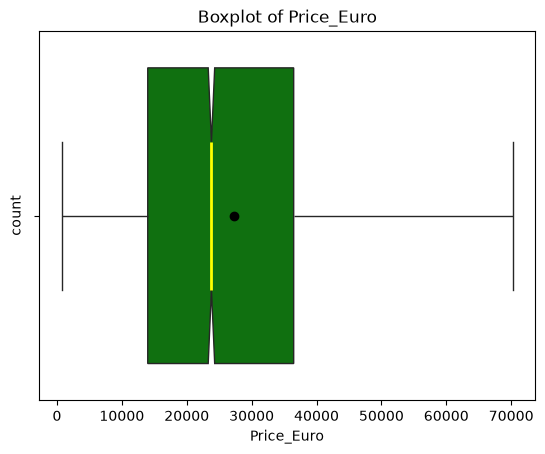

In [43]:
#Figure7
plt.Figure(figsize=(10,7))
Figure7=sns.boxplot(x=df['Price_Euro'],color='green',notch=True,showmeans=True,meanprops=dict(marker='o',markerfacecolor='black',markeredgecolor='black'),medianprops=dict(linewidth=2,color='yellow'))
plt.xlabel('Price_Euro')
plt.ylabel('count')
plt.title('Boxplot of Price_Euro')
plt.show()

In [42]:
#Figure8(Imshow for numerical data)
Figure8=px.imshow(df.corr(numeric_only=True),color_continuous_scale='Reds',text_auto=True,title='Corr between numerical data')
Figure8.update_layout(title_x=0.5,template='plotly_dark')
Figure8.show()

In [46]:
from plotly.subplots import make_subplots

print(make_subplots)
print(type(make_subplots))

<function make_subplots at 0x00000212CB2B5B10>
<class 'function'>


In [48]:
fig = make_subplots(
    rows=3,
    cols=3,
    specs=[
        [{"type": "domain"}, {"type": "domain"}, {"type": "domain"}],  # Row 1: 3 KPIs widgets
        [{"type": "xy"}, {"type": "xy"}, {"type": "xy"}],          # Row 2: Charts 1, 2, 3
        [{"type": "xy"}, {"type": "domain"}, {"type": "domain"}]   # Row 3: Charts 4, 5, 6
    ],
    subplot_titles=(
        "", "", "",  # Empty titles for KPI row
        "Price Over Models", "Average Price Over Years", "Price vs KM",  # Row 2 chart titles
                "Distribution of Price", "Fuel Type", "Distribution of Transmission"          # Row 3 chart titles
        ),
    vertical_spacing=0.12,
    horizontal_spacing=0.08,
    row_heights=[0.25, 0.37, 0.38]
)

# ==========================================
# 4. Add 3 KPIs to Row 1
# ==========================================
# KPI 1: Total Cars Listed
fig.add_trace(KPI1, row=1, col=1)

# KPI 2: Average Price
fig.add_trace(KPI2, row=1, col=2)

# KPI 3: Average Mileage
fig.add_trace(KPI3, row=1, col=3)


# ==========================================
# 5. Add 6 Charts to Rows 2 & 3
# ==========================================

# Chart 1 (Row 2, Col 1): Bar Chart - Price by Model
for trace in Figure2.data:
    fig.add_trace(trace, row=2, col=1)

# Chart 2 (Row 2, Col 2): Line Chart - Price Over Years
for trace in Figure1.data:
    fig.add_trace(trace, row=2, col=2)

# Chart 3 (Row 2, Col 3): Scatter Chart - Price vs Mileage
for trace in Figure5.data:
    fig.add_trace(trace, row=2, col=3)

# Chart 4 (Row 3, Col 1): Histogram - Horse Power Distribution
for trace in Figure6.data:
    fig.add_trace(trace, row=3, col=1)

# Chart 5 (Row 3, Col 2): Pie Chart - Fuel Type Share
for trace in Figure4.data:
    fig.add_trace(trace, row=3, col=2)

# Chart 6 (Row 3, Col 3): Donut Chart - Transmission Share
for trace in Figure3.data:
    fig.add_trace(trace, row=3, col=3)


# ==========================================
# 6. Apply Final Formatting and Export
# ==========================================
fig.update_layout(
    template='plotly_dark',
    height=1100,
    title_text="Mercedes Analytics Dashboard",
    showlegend=False
)

# Display the dashboard interactive figure
fig.update_layout(title_x=0.5)
fig.show()

# Save the final dashboard as an interactive HTML file
fig.write_html('Mercedes_dashboard_3x3.html')

## Conclusion

This project provided an end-to-end analysis of Mercedes-Benz car data, starting with data inspection and cleaning, followed by exploratory data analysis, visualization, and the development of an interactive dashboard.

Using Python and its data analysis libraries, I explored car prices, mileage, manufacturing years, vehicle models, fuel types, and transmission systems to identify patterns and understand the relationships between different vehicle characteristics.

The final interactive dashboard brings the key metrics and visual insights together in one place, making the results easier to explore and interpret.

Through this project, I strengthened my practical skills in data cleaning, handling missing values, outlier treatment, exploratory data analysis, data visualization, and interactive dashboard development.

**This project demonstrates how raw automotive data can be transformed into meaningful insights that support better understanding of the used-car market.**